# Stroke Prediction Using Logistic Regression

## Project overview
This project uses the `healthcare-dataset-stroke-data.csv` dataset to explore whether patient information can help predict the likelihood of a recorded stroke outcome. A Logistic Regression classifier is trained and evaluated.

**Important:** This is an educational machine-learning project, not a medical diagnostic tool. Predictions must not be used to diagnose, treat, or make healthcare decisions.

## 1. Import libraries
The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for visualisation, and scikit-learn for preprocessing, model training, and evaluation.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

## 2. Load the dataset
Place `healthcare-dataset-stroke-data.csv` in the same folder as this notebook before running it.

In [2]:
DATA_PATH = "healthcare-dataset-stroke-data.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Explore and prepare the data
The target column is `stroke`. The `id` column is an identifier rather than a patient characteristic, so it is excluded from model training. The dataset has missing BMI values and an uneven distribution between the two target classes; the preprocessing pipeline handles missing values and the model uses class weighting.

In [3]:
print("Column information:")
df.info()

print("\\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\\nStroke class counts:")
display(df["stroke"].value_counts().rename(index={0: "No stroke", 1: "Stroke"}).to_frame("count"))

print("\\nStroke class percentages:")
display((df["stroke"].value_counts(normalize=True) * 100).round(2).rename(index={0: "No stroke", 1: "Stroke"}).to_frame("percentage"))

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
\nMissing values:


,missing_values
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


\nStroke class counts:


,count
stroke,
No stroke,4861
Stroke,249


\nStroke class percentages:


,percentage
stroke,
No stroke,95.13
Stroke,4.87


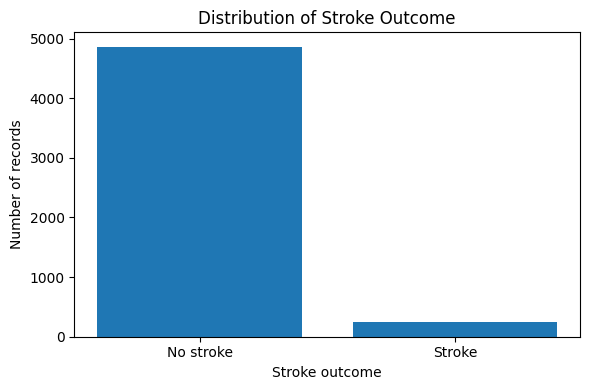

In [4]:
counts = df["stroke"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["No stroke", "Stroke"], counts.values)
plt.title("Distribution of Stroke Outcome")
plt.xlabel("Stroke outcome")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

## 4. Split features and target
A stratified train-test split keeps approximately the same class proportions in both sets. The test set is held back until evaluation.

In [5]:
X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Numeric features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Training rows: 4088
Testing rows: 1022


## 5. Preprocess the features
Numeric missing values are filled using the median and then scaled. Categorical missing values are filled using the most frequent value and categories are one-hot encoded. All preprocessing is fitted only on the training data through a scikit-learn pipeline.

In [6]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## 6. Train the Logistic Regression model
`class_weight="balanced"` gives additional weight to the less frequent stroke class during training. This can help the classifier pay more attention to the minority class, although it does not guarantee good stroke detection.

In [7]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 7. Evaluate the model
Accuracy alone can be misleading when one class is much more common. Therefore, precision, recall, F1-score, ROC-AUC, average precision, and the confusion matrix are also reported.

In [8]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_probability),
    "Average precision": average_precision_score(y_test, y_probability)
}

metrics_df = pd.DataFrame.from_dict(metrics, orient="index", columns=["Score"])
display(metrics_df.round(4))

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["No stroke", "Stroke"], zero_division=0))

,Score
Accuracy,0.7456
Precision,0.1379
Recall,0.8000
F1-score,0.2353
ROC-AUC,0.8437
Average precision,0.2685


Classification report:
              precision    recall  f1-score   support

   No stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



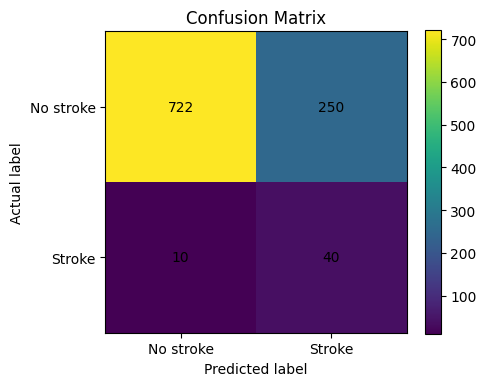

In [9]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, interpolation="nearest")
ax.figure.colorbar(image, ax=ax)
ax.set(xticks=np.arange(2), yticks=np.arange(2),
       xticklabels=["No stroke", "Stroke"],
       yticklabels=["No stroke", "Stroke"],
       title="Confusion Matrix", xlabel="Predicted label", ylabel="Actual label")
for i in range(2):
    for j in range(2):
        ax.text(j, i, format(cm[i, j], "d"), ha="center", va="center")
plt.tight_layout()
plt.show()

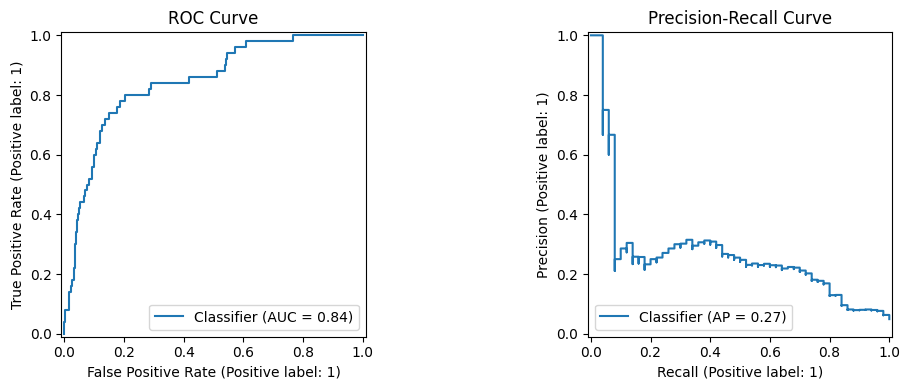

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
RocCurveDisplay.from_predictions(y_test, y_probability, ax=axes[0])
axes[0].set_title("ROC Curve")
PrecisionRecallDisplay.from_predictions(y_test, y_probability, ax=axes[1])
axes[1].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

## 8. Discussion and limitations
- The target classes are imbalanced, so accuracy should not be used as the only measure of performance.
- Class weighting is one approach to address class imbalance, but the model may still miss some stroke cases or produce false alarms.
- Logistic Regression models a relatively simple relationship between the input features and the outcome; it may not capture complex patterns.
- The dataset may contain sampling, measurement, and demographic limitations. Results on this dataset may not generalise to other populations or healthcare settings.
- A prediction from this model is not a diagnosis and must not replace assessment by a qualified healthcare professional.

## 9. Conclusion
This notebook demonstrates a complete machine-learning workflow: loading data, exploring class balance and missing values, preprocessing numerical and categorical variables, training Logistic Regression, and evaluating performance using multiple metrics. The evaluation results should be interpreted cautiously, especially because stroke records are much less common than non-stroke records.